## LaDe 18: Multi Courier Pickup Ordering (Flag 18)

### Dataset Overview

Constructed LaDe-style Shanghai case: 669 tasks, 3 courier(s), 24 courier-workday trajectories and 58683 GPS points. Routes follow the archived local OSM street network with oneway directions respected; restricted-access ways and expressways are excluded. Turn-restriction relations are not modeled. AOIs are constructed road-centered catchments, not official polygons. All times are local Shanghai time. Each task is accepted before selection and completion; the full candidate table records every pending task at each decision. speed_kmh is the mean speed of the immediately preceding GPS segment (zero during waiting/service), not an instantaneous endpoint speed. Empty last_near_destination_before_acceptance means no prior GPS observation within 250 m. Deadline-expired observations remain valid and represent late tasks; this is not an all-on-time dataset. Pickup-event GPS positions are separately constructed sensor observations with measurement errors; they are not the coordinates used to construct the continuous road trajectory.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Find pickup-task handling patterns in the selected service region.

Role: Last-mile courier operations analyst


Category: multi_courier_pickup_ordering


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "pickup_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Do couriers differ in acceptance/pickup ordering on matched-volume days serving the same AOIs?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

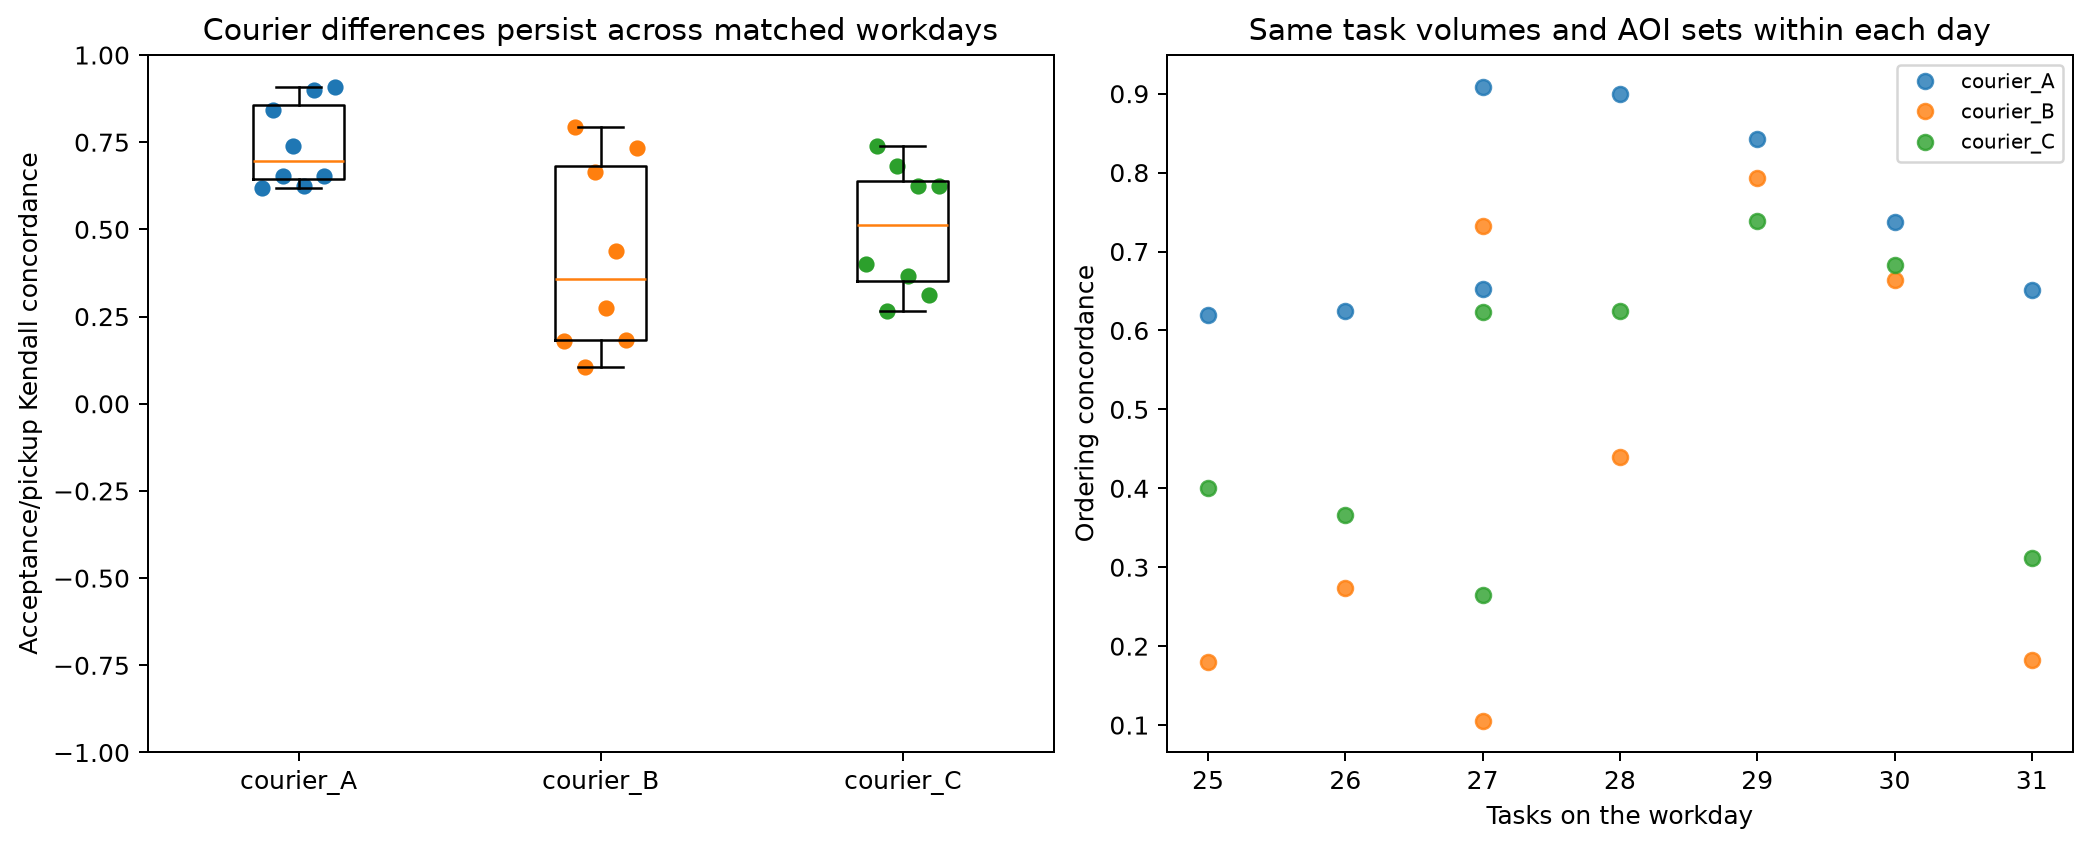

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

decisions = pd.read_csv("decision_candidates.csv")


def courier_order(df, user_df, decisions):
    rows = []
    for (courier, day), q in df.groupby(["courier_id", "service_date"]):
        rows.append(
            {
                "courier": courier,
                "day": day,
                "tasks": len(q),
                "concordance": float(
                    kendalltau(q.acceptance_order, q.completion_order).statistic
                ),
            }
        )
    daily = pd.DataFrame(rows)
    couriers = sorted(daily.courier.unique())
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), constrained_layout=True)
    axes[0].boxplot(
        [daily[daily.courier.eq(c)].concordance for c in couriers], tick_labels=couriers
    )
    for i, c in enumerate(couriers, 1):
        q = daily[daily.courier.eq(c)]
        axes[0].scatter(i + np.linspace(-0.12, 0.12, len(q)), q.concordance, s=30)
        axes[1].plot(q.tasks, q.concordance, "o", label=c, alpha=0.8)
    axes[0].set(
        ylabel="Acceptance/pickup Kendall concordance",
        title="Courier differences persist across matched workdays",
        ylim=(-1, 1),
    )
    axes[1].set(
        xlabel="Tasks on the workday",
        ylabel="Ordering concordance",
        title="Same task volumes and AOI sets within each day",
    )
    axes[1].legend(fontsize=8)
    return {
        "courier_days": len(daily),
        "daily_task_range": [int(daily.tasks.min()), int(daily.tasks.max())],
        "mean_concordance_by_courier": (
            daily.groupby("courier").concordance.mean().to_dict()
        ),
    }


evidence = courier_order(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "courier_order",
  "insight": "Couriers serving the same AOIs differ in how closely their pickup order follows task acceptance order, even on days with similar task volumes.",
  "insight_type": "overall_pattern",
  "insight_value": {
    "courier_days": 24,
    "daily_task_range": [
      25,
      31
    ],
    "mean_concordance_by_courier": {
      "courier_A": 0.7421560393835144,
      "courier_B": 0.42135917423737224,
      "courier_C": 0.5016105241522372
    }
  },
  "question": "Do couriers differ in acceptance/pickup ordering on matched-volume days serving the same AOIs?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Do couriers differ in acceptance/pickup ordering on matched-volume days serving the same AOIs?",
    "file": "visualizations/insight_1.png",
    "description": "All panels and displayed statistics are computed from the emitted CSV files."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom scipy.stats import kendalltau\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef courier_order(df,user_df,decisions):\n    rows=[]\n    for (courier,day),q in df.groupby(['courier_id','service_date']):\n        rows.append({'courier':courier,'day':day,'tasks':len(q),\n                     'concordance':float(kendalltau(q.acceptance_order,q.completion_order).statistic)})\n    daily=pd.DataFrame(rows);couriers=sorted(daily.courier.unique())\n    fig,axes=plt.subplots(1,2,figsize=(11.5,4.6),constrained_layout=True)\n    axes[0].boxplot([daily[daily.courier.eq(c)].concordance for c in couriers],tick_labels=couriers)\n    for i,c in enumerate(couriers,1):\n        q=daily[daily.courier.eq(c)];axes[0].scatter(i+np.linspace(-.12,.12,len(q)),q.concordance,s=30)\n        axes[1].plot(q.tasks,q.concordance,'o',label=c,alpha=.8)\n    axes[0].set(ylabel='Acceptance/pickup Kendall concordance',title='Courier differences persist across matched workdays',ylim=(-1,1))\n    axes[1].set(xlabel='Tasks on the workday',ylabel='Ordering concordance',title='Same task volumes and AOI sets within each day');axes[1].legend(fontsize=8)\n    return {'courier_days':len(daily),'daily_task_range':[int(daily.tasks.min()),int(daily.tasks.max())],\n            'mean_concordance_by_courier':daily.groupby('courier').concordance.mean().to_dict()}\n\nevidence = courier_order(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "aoi_id",
    "accept_time",
    "pickup_time",
    "task_id"
  ]
}

### **Question 2**: Does acceptance-location distance predict deferral, and how does that comparison change as windows end?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

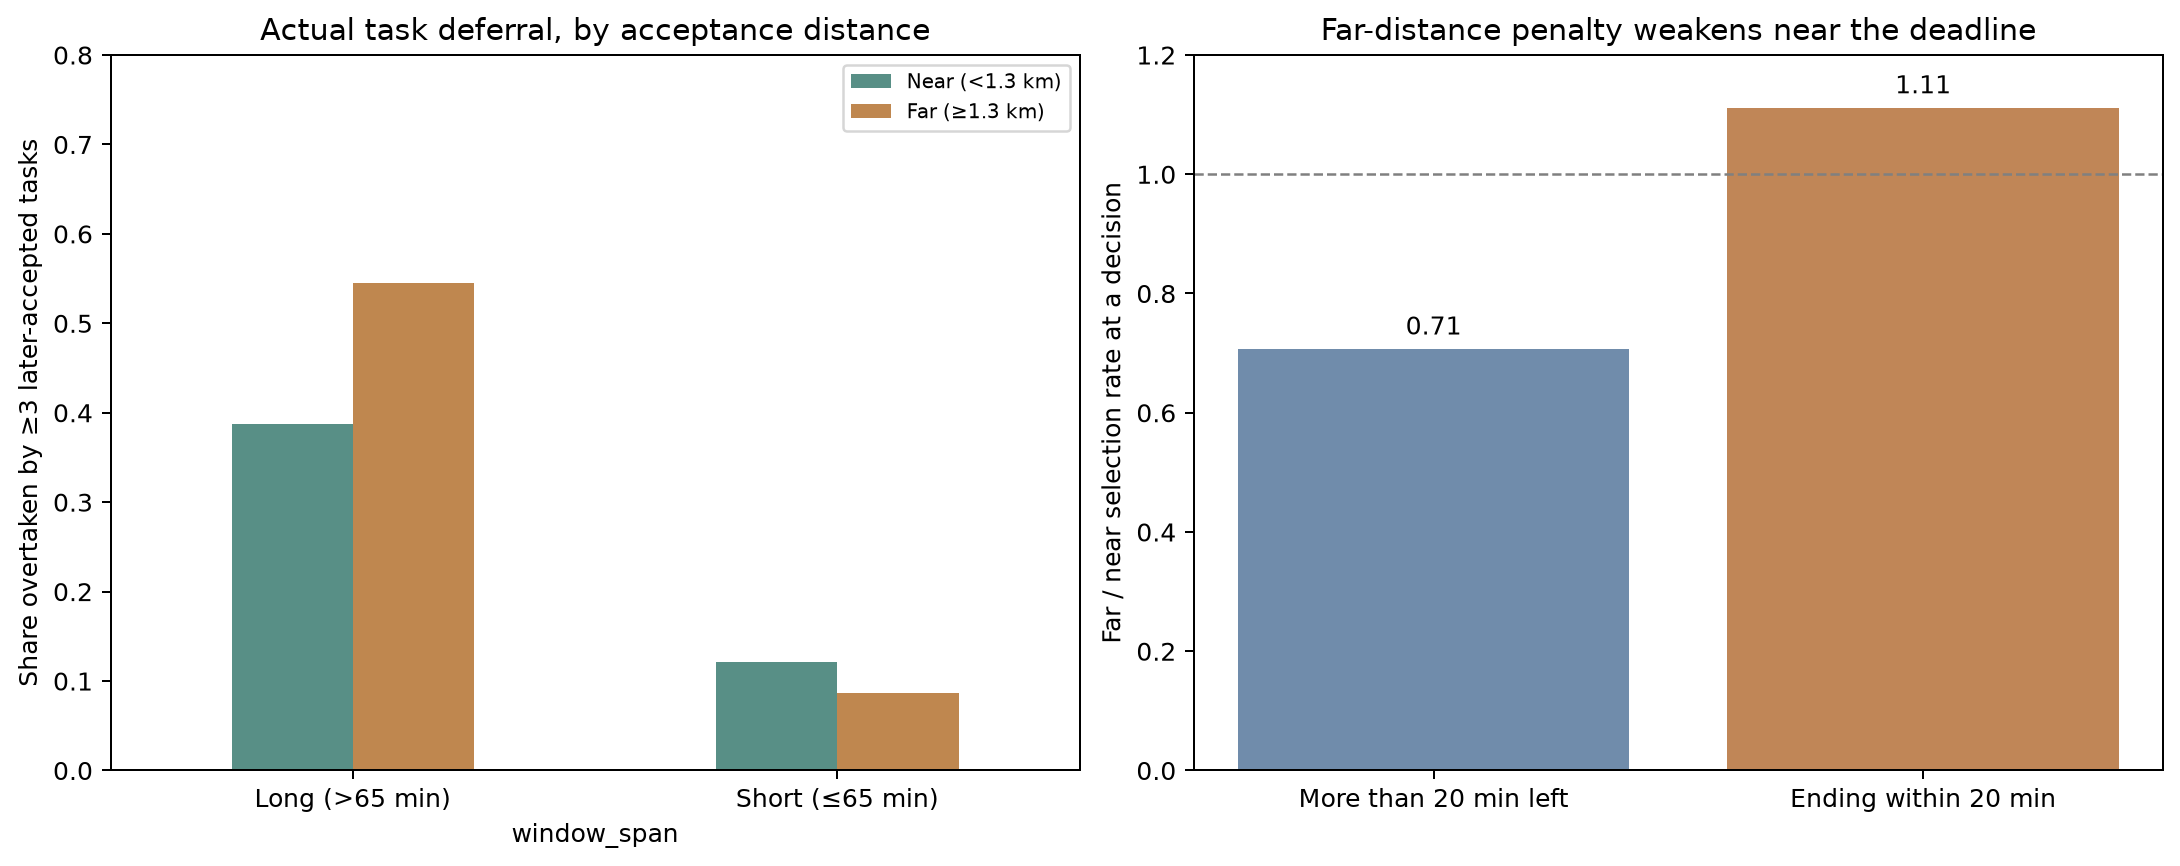

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

decisions = pd.read_csv("decision_candidates.csv")


def distance_urgency(df, user_df, decisions):
    d = decisions.merge(
        df[["task_id", "acceptance_distance_km"]],
        left_on="candidate_task_id",
        right_on="task_id",
        validate="many_to_one",
    )
    d = d[d.pending_count >= 4].copy()
    d["acceptance_location"] = np.where(
        d.acceptance_distance_km >= 1.3, "Far (≥1.3 km)", "Near (<1.3 km)"
    )
    d["window"] = np.where(
        d.remaining_window_min <= 20, "Ending within 20 min", "More than 20 min"
    )
    rates = d.groupby(["window", "acceptance_location"]).selected.mean().unstack()
    rates = rates.reindex(["More than 20 min", "Ending within 20 min"])
    tasks = df.copy()
    tasks["overtaken"] = 0
    for _, q in tasks.groupby("trajectory_id"):
        for index, row in q.iterrows():
            tasks.loc[index, "overtaken"] = int(
                (
                    (q.acceptance_order > row.acceptance_order)
                    & (q.completion_order < row.completion_order)
                ).sum()
            )
    tasks["deferred"] = tasks.overtaken >= 3
    tasks["location"] = np.where(
        tasks.acceptance_distance_km >= 1.3, "Far (≥1.3 km)", "Near (<1.3 km)"
    )
    span = (
        pd.to_datetime(tasks.window_end, format="mixed")
        - pd.to_datetime(tasks.accept_time, format="mixed")
    ).dt.total_seconds() / 60
    tasks["window_span"] = np.where(span <= 65, "Short (≤65 min)", "Long (>65 min)")
    actual = tasks.groupby(["window_span", "location"]).deferred.mean().unstack()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
    actual.reindex(["Long (>65 min)", "Short (≤65 min)"])[
        ["Near (<1.3 km)", "Far (≥1.3 km)"]
    ].plot.bar(ax=axes[0], rot=0, color=["#588f86", "#bf874f"])
    axes[0].set(
        ylabel="Share overtaken by ≥3 later-accepted tasks",
        title="Actual task deferral, by acceptance distance",
        ylim=(0, 0.8),
    )
    axes[0].legend(fontsize=8)
    ratio = rates["Far (≥1.3 km)"] / rates["Near (<1.3 km)"]
    axes[1].bar(
        ["More than 20 min left", "Ending within 20 min"],
        ratio,
        color=["#708cab", "#c08657"],
    )
    axes[1].axhline(1, color="gray", ls="--", lw=1)
    for i, value in enumerate(ratio):
        axes[1].text(i, value + 0.025, f"{value:.2f}", ha="center")
    axes[1].set(
        ylabel="Far / near selection rate at a decision",
        title="Far-distance penalty weakens near the deadline",
        ylim=(0, 1.2),
    )
    normal = rates.loc["More than 20 min"]
    urgent = rates.loc["Ending within 20 min"]
    return {
        "unit": (
            "pending candidate at a decision with at least four tasks; lower selection"
            " rate means more deferral"
        ),
        "candidate_opportunities": len(d),
        "selected_rates": rates.to_dict(),
        "actual_task_deferral_rates": actual.to_dict(),
        "far_to_near_selection_ratio": ratio.to_dict(),
        "near_minus_far_gap_loose": float(
            normal["Near (<1.3 km)"] - normal["Far (≥1.3 km)"]
        ),
        "near_minus_far_gap_urgent": float(
            urgent["Near (<1.3 km)"] - urgent["Far (≥1.3 km)"]
        ),
    }


evidence = distance_urgency(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (8 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "distance_urgency",
  "insight": "Tasks accepted farther from their pickup locations are more likely to be deferred, but this pattern weakens when their service windows are close to ending.",
  "insight_type": "factor_relationship",
  "insight_value": {
    "unit": "pending candidate at a decision with at least four tasks; lower selection rate means more deferral",
    "candidate_opportunities": 9558,
    "selected_rates": {
      "Far (≥1.3 km)": {
        "More than 20 min": 0.04896142433234421,
        "Ending within 20 min": 0.76
      },
      "Near (<1.3 km)": {
        "More than 20 min": 0.06933019976498238,
        "Ending within 20 min": 0.6842105263157895
      }
    },
    "actual_task_deferral_rates": {
      "Far (≥1.3 km)": {
        "Long (>65 min)": 0.5449275362318841,
        "Short (≤65 min)": 0.08695652173913043
      },
      "Near (<1.3 km)": {
        "Long (>65 min)": 0.3877551020408163,
        "Short (≤65 min)": 0.12121212121212122
      }
    },
    "far_to_near_selection_ratio": {
      "More than 20 min": 0.7062063068953377,
      "Ending within 20 min": 1.1107692307692307
    },
    "near_minus_far_gap_loose": 0.020368775432638167,
    "near_minus_far_gap_urgent": -0.07578947368421052
  },
  "question": "Does acceptance-location distance predict deferral, and how does that comparison change as windows end?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Does acceptance-location distance predict deferral, and how does that comparison change as windows end?",
    "file": "visualizations/insight_2.png",
    "description": "All panels and displayed statistics are computed from the emitted CSV files."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom scipy.stats import kendalltau\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef distance_urgency(df,user_df,decisions):\n    d=decisions.merge(df[['task_id','acceptance_distance_km']],left_on='candidate_task_id',right_on='task_id',validate='many_to_one')\n    d=d[d.pending_count>=4].copy();d['acceptance_location']=np.where(d.acceptance_distance_km>=1.3,'Far (≥1.3 km)','Near (<1.3 km)')\n    d['window']=np.where(d.remaining_window_min<=20,'Ending within 20 min','More than 20 min')\n    rates=d.groupby(['window','acceptance_location']).selected.mean().unstack()\n    rates=rates.reindex(['More than 20 min','Ending within 20 min'])\n    tasks=df.copy();tasks['overtaken']=0\n    for _,q in tasks.groupby('trajectory_id'):\n        for index,row in q.iterrows():\n            tasks.loc[index,'overtaken']=int(((q.acceptance_order>row.acceptance_order)&(q.completion_order<row.completion_order)).sum())\n    tasks['deferred']=tasks.overtaken>=3\n    tasks['location']=np.where(tasks.acceptance_distance_km>=1.3,'Far (≥1.3 km)','Near (<1.3 km)')\n    span=(pd.to_datetime(tasks.window_end,format='mixed')-pd.to_datetime(tasks.accept_time,format='mixed')).dt.total_seconds()/60\n    tasks['window_span']=np.where(span<=65,'Short (≤65 min)','Long (>65 min)')\n    actual=tasks.groupby(['window_span','location']).deferred.mean().unstack()\n    fig,axes=plt.subplots(1,2,figsize=(12,4.7),constrained_layout=True)\n    actual.reindex(['Long (>65 min)','Short (≤65 min)'])[['Near (<1.3 km)','Far (≥1.3 km)']].plot.bar(ax=axes[0],rot=0,color=['#588f86','#bf874f'])\n    axes[0].set(ylabel='Share overtaken by ≥3 later-accepted tasks',title='Actual task deferral, by acceptance distance',ylim=(0,.8));axes[0].legend(fontsize=8)\n    ratio=rates['Far (≥1.3 km)']/rates['Near (<1.3 km)']\n    axes[1].bar(['More than 20 min left','Ending within 20 min'],ratio,color=['#708cab','#c08657'])\n    axes[1].axhline(1,color='gray',ls='--',lw=1)\n    for i,value in enumerate(ratio):axes[1].text(i,value+.025,f'{value:.2f}',ha='center')\n    axes[1].set(ylabel='Far / near selection rate at a decision',title='Far-distance penalty weakens near the deadline',ylim=(0,1.2))\n    normal=rates.loc['More than 20 min'];urgent=rates.loc['Ending within 20 min']\n    return {'unit':'pending candidate at a decision with at least four tasks; lower selection rate means more deferral',\n            'candidate_opportunities':len(d),'selected_rates':rates.to_dict(),\n            'actual_task_deferral_rates':actual.to_dict(),'far_to_near_selection_ratio':ratio.to_dict(),\n            'near_minus_far_gap_loose':float(normal['Near (<1.3 km)']-normal['Far (≥1.3 km)']),\n            'near_minus_far_gap_urgent':float(urgent['Near (<1.3 km)']-urgent['Far (≥1.3 km)'])}\n\nevidence = distance_urgency(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 8,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "time_window_end",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 3**: Within each courier, how does ordering differ across AOI sets, and are local patterns more stable in every-day AOIs?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

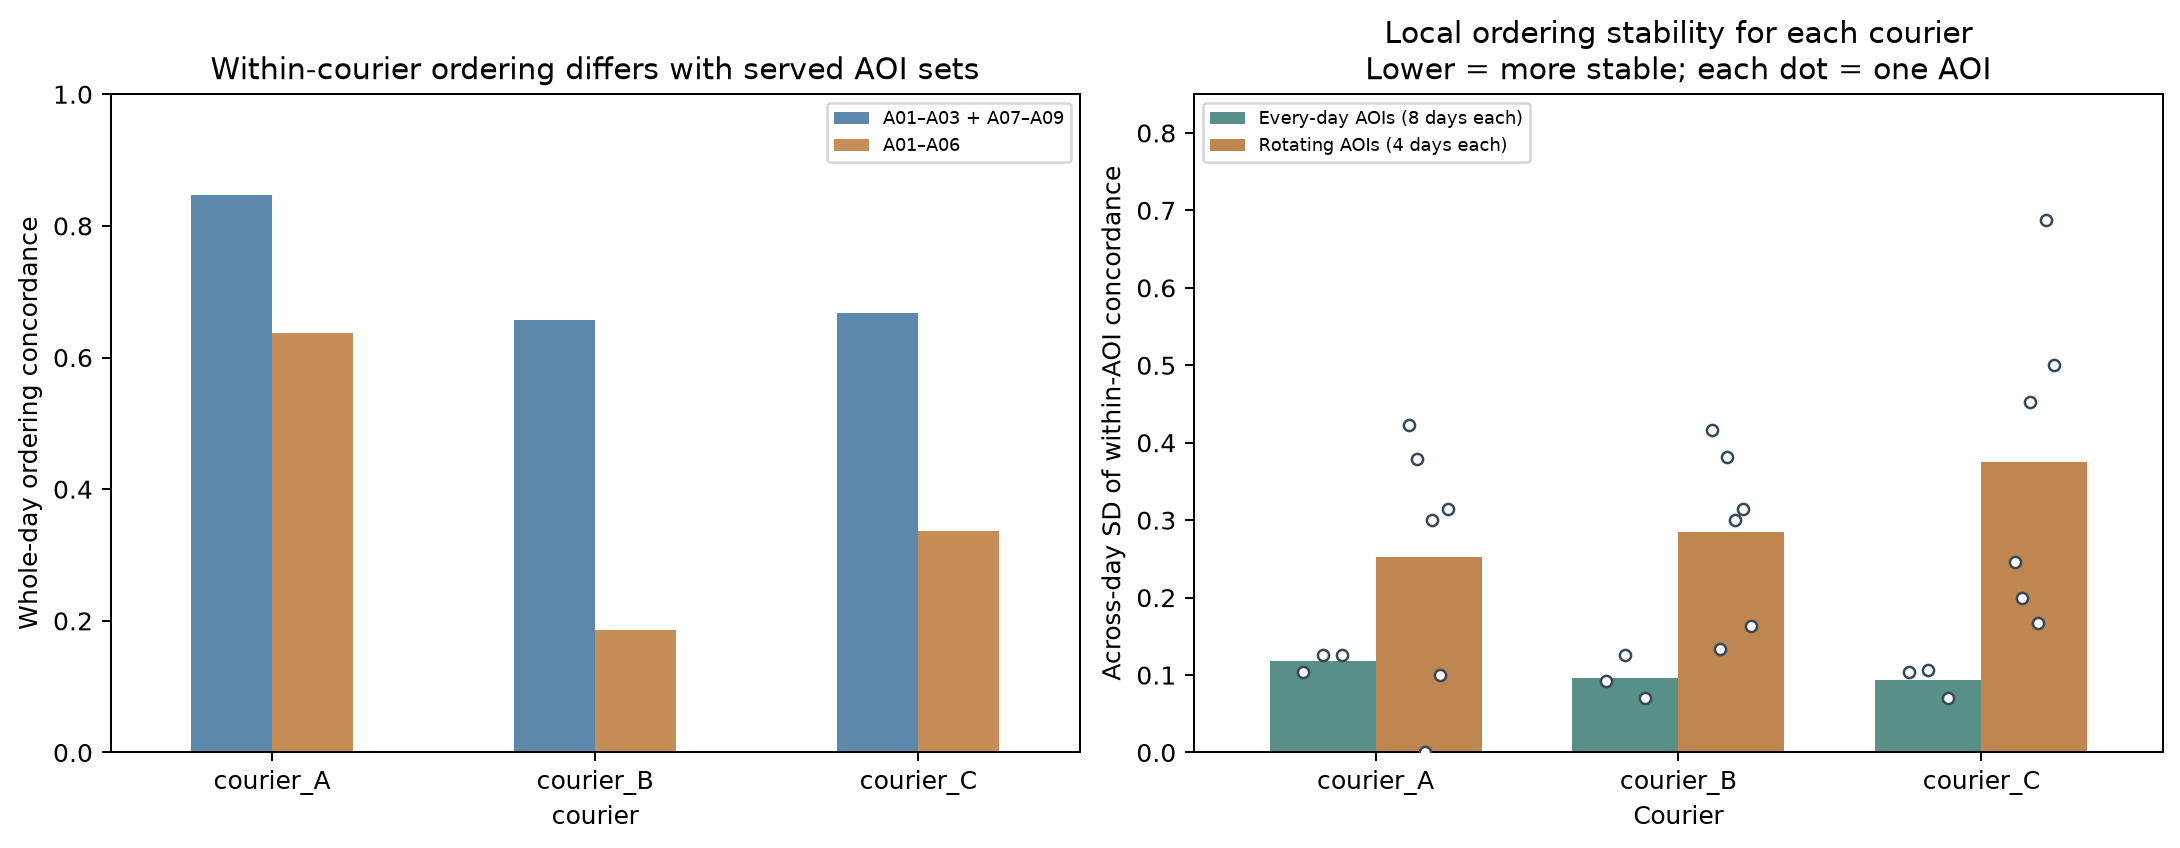

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

decisions = pd.read_csv("decision_candidates.csv")


def aoi_day_order(df, user_df, decisions):
    rows = []
    local = []
    for (courier, day), q in df.groupby(["courier_id", "service_date"]):
        mix = "A01–A06" if "A04" in set(q.aoi_id) else "A01–A03 + A07–A09"
        rows.append(
            {
                "courier": courier,
                "day": day,
                "aoi_set": mix,
                "tau": float(
                    kendalltau(q.acceptance_order, q.completion_order).statistic
                ),
            }
        )
        for aoi, r in q.groupby("aoi_id"):
            local.append(
                {
                    "courier": courier,
                    "day": day,
                    "aoi": aoi,
                    "group": (
                        "Every-day AOIs"
                        if aoi in ["A01", "A02", "A03"]
                        else "Rotating AOIs"
                    ),
                    "tau": float(
                        kendalltau(r.acceptance_order, r.completion_order).statistic
                    ),
                }
            )
    daily = pd.DataFrame(rows)
    local = pd.DataFrame(local)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
    table = daily.groupby(["courier", "aoi_set"]).tau.mean().unstack()
    table.plot.bar(ax=axes[0], rot=0, color=["#5c88ab", "#c68d57"])
    axes[0].set(
        ylabel="Whole-day ordering concordance",
        title="Within-courier ordering differs with served AOI sets",
        ylim=(0, 1),
    )
    axes[0].legend(fontsize=7)
    names = ["Every-day AOIs", "Rotating AOIs"]
    # Measure temporal variability within each courier/AOI first, rather than
    # pooling different couriers and different AOIs into one distribution.
    stability = (
        local.groupby(["courier", "aoi", "group"])
        .tau.agg(["std", "count"])
        .reset_index()
    )
    by_courier = stability.groupby(["courier", "group"])["std"].mean().unstack()[names]
    by_courier.plot.bar(ax=axes[1], rot=0, color=["#588f86", "#bf874f"], width=0.7)
    bar_handles, _ = axes[1].get_legend_handles_labels()
    for i, courier in enumerate(by_courier.index):
        for j, name in enumerate(names):
            x = i + (-0.175 if j == 0 else 0.175)
            values = stability[
                (stability.courier == courier) & (stability.group == name)
            ]["std"].to_numpy()
            axes[1].scatter(
                x + np.linspace(-0.065, 0.065, len(values)),
                values,
                s=20,
                facecolors="white",
                edgecolors="#35495a",
                zorder=3,
            )
    axes[1].set(
        xlabel="Courier",
        ylabel="Across-day SD of within-AOI concordance",
        title=(
            "Local ordering stability for each courier\nLower = more stable; each dot ="
            " one AOI"
        ),
        ylim=(0, 0.85),
    )
    axes[1].legend(
        bar_handles,
        ["Every-day AOIs (8 days each)", "Rotating AOIs (4 days each)"],
        fontsize=7,
        loc="upper left",
    )
    return {
        "whole_day_mean_concordance": table.to_dict(),
        "local_concordance_mean": local.groupby("group").tau.mean().to_dict(),
        "local_concordance_sd": local.groupby("group").tau.std().to_dict(),
        "mean_within_aoi_across_day_sd_by_courier": by_courier.to_dict(),
        "stability_unit": (
            "Compute sample SD across days separately for each courier and AOI, then"
            " average AOI SDs within each courier/group."
        ),
    }


evidence = aoi_day_order(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "aoi_day_order",
  "insight": "For the same courier, pickup ordering changes across workdays as the set of served AOIs changes, while repeatedly served AOIs retain more stable local patterns.",
  "insight_type": "factor_relationship",
  "insight_value": {
    "whole_day_mean_concordance": {
      "A01–A03 + A07–A09": {
        "courier_A": 0.8471495937013178,
        "courier_B": 0.6572046089287469,
        "courier_C": 0.6674862812793847
      },
      "A01–A06": {
        "courier_A": 0.6371624850657109,
        "courier_B": 0.18551373954599762,
        "courier_C": 0.33573476702508964
      }
    },
    "local_concordance_mean": {
      "Every-day AOIs": 0.9138888888888889,
      "Rotating AOIs": 0.6324074074074074
    },
    "local_concordance_sd": {
      "Every-day AOIs": 0.10873436066560725,
      "Rotating AOIs": 0.42252583598246746
    },
    "mean_within_aoi_across_day_sd_by_courier": {
      "Every-day AOIs": {
        "courier_A": 0.11828513968392178,
        "courier_B": 0.096321826890372,
        "courier_C": 0.09370833626165924
      },
      "Rotating AOIs": {
        "courier_A": 0.25266875202281486,
        "courier_B": 0.284669764437517,
        "courier_C": 0.37513033618089153
      }
    },
    "stability_unit": "Compute sample SD across days separately for each courier and AOI, then average AOI SDs within each courier/group."
  },
  "question": "Within each courier, how does ordering differ across AOI sets, and are local patterns more stable in every-day AOIs?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Within each courier, how does ordering differ across AOI sets, and are local patterns more stable in every-day AOIs?",
    "file": "visualizations/insight_3.png",
    "description": "All panels and displayed statistics are computed from the emitted CSV files."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom scipy.stats import kendalltau\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef aoi_day_order(df,user_df,decisions):\n    rows=[];local=[]\n    for (courier,day),q in df.groupby(['courier_id','service_date']):\n        mix='A01–A06' if 'A04' in set(q.aoi_id) else 'A01–A03 + A07–A09'\n        rows.append({'courier':courier,'day':day,'aoi_set':mix,\n                     'tau':float(kendalltau(q.acceptance_order,q.completion_order).statistic)})\n        for aoi,r in q.groupby('aoi_id'):\n            local.append({'courier':courier,'day':day,'aoi':aoi,\n                'group':'Every-day AOIs' if aoi in ['A01','A02','A03'] else 'Rotating AOIs',\n                'tau':float(kendalltau(r.acceptance_order,r.completion_order).statistic)})\n    daily=pd.DataFrame(rows);local=pd.DataFrame(local)\n    fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)\n    table=daily.groupby(['courier','aoi_set']).tau.mean().unstack()\n    table.plot.bar(ax=axes[0],rot=0,color=['#5c88ab','#c68d57'])\n    axes[0].set(ylabel='Whole-day ordering concordance',title='Within-courier ordering differs with served AOI sets',ylim=(0,1));axes[0].legend(fontsize=7)\n    names=['Every-day AOIs','Rotating AOIs']\n    # Measure temporal variability within each courier/AOI first, rather than\n    # pooling different couriers and different AOIs into one distribution.\n    stability=local.groupby(['courier','aoi','group']).tau.agg(['std','count']).reset_index()\n    by_courier=stability.groupby(['courier','group'])['std'].mean().unstack()[names]\n    by_courier.plot.bar(ax=axes[1],rot=0,color=['#588f86','#bf874f'],width=.7)\n    bar_handles,_=axes[1].get_legend_handles_labels()\n    for i,courier in enumerate(by_courier.index):\n        for j,name in enumerate(names):\n            x=i+(-.175 if j==0 else .175)\n            values=stability[(stability.courier==courier)&(stability.group==name)]['std'].to_numpy()\n            axes[1].scatter(x+np.linspace(-.065,.065,len(values)),values,\n                s=20,facecolors='white',edgecolors='#35495a',zorder=3)\n    axes[1].set(xlabel='Courier',ylabel='Across-day SD of within-AOI concordance',\n        title='Local ordering stability for each courier\\nLower = more stable; each dot = one AOI',ylim=(0,.85))\n    axes[1].legend(bar_handles,['Every-day AOIs (8 days each)','Rotating AOIs (4 days each)'],fontsize=7,loc='upper left')\n    return {'whole_day_mean_concordance':table.to_dict(),'local_concordance_mean':local.groupby('group').tau.mean().to_dict(),\n            'local_concordance_sd':local.groupby('group').tau.std().to_dict(),\n            'mean_within_aoi_across_day_sd_by_courier':by_courier.to_dict(),\n            'stability_unit':'Compute sample SD across days separately for each courier and AOI, then average AOI SDs within each courier/group.'}\n\nevidence = aoi_day_order(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "aoi_id",
    "accept_time",
    "pickup_time",
    "task_id"
  ]
}

### **Question 4**: Are large task-to-pickup-event GPS mismatches spread evenly across AOIs?

#### Analysis action

Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.

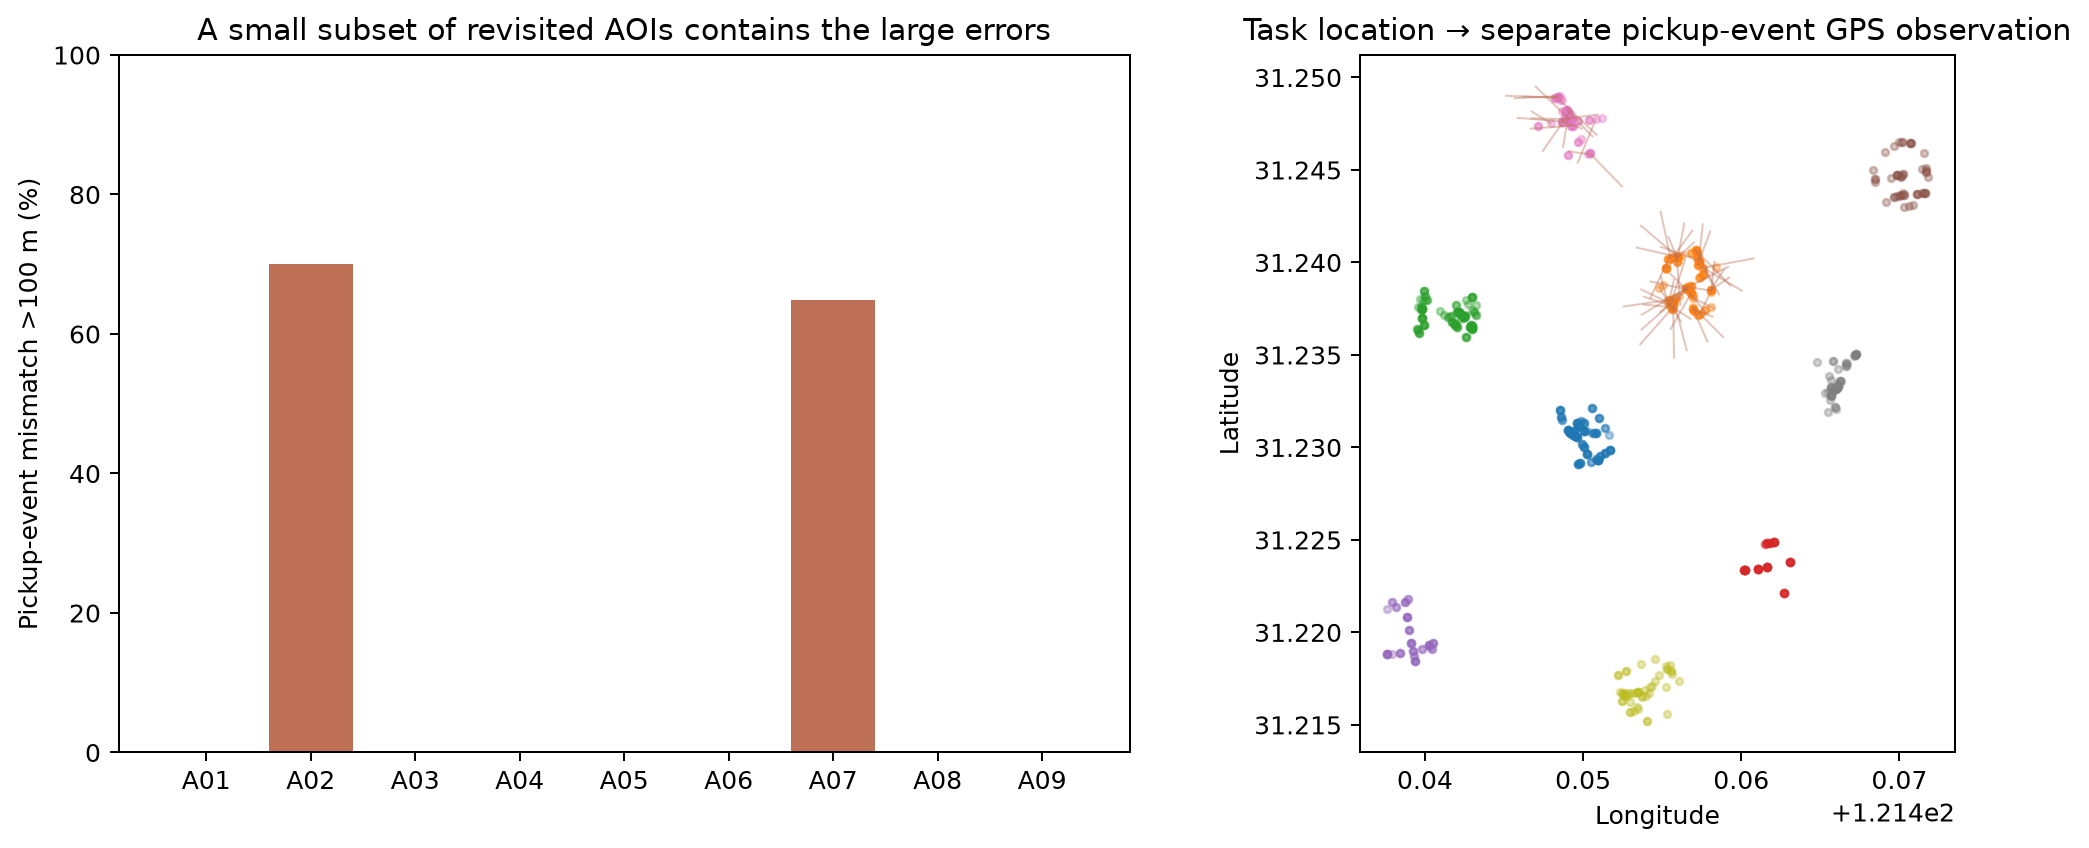

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

decisions = pd.read_csv("decision_candidates.csv")


def event_gps_mismatch(df, user_df, decisions):
    d = df.copy()
    a = np.radians(d[["task_lng", "task_lat"]].to_numpy())
    b = np.radians(d[["pickup_gps_lng", "pickup_gps_lat"]].to_numpy())
    diff = b - a
    d["mismatch_m"] = (
        6371008.8
        * 2
        * np.arcsin(
            np.sqrt(
                np.sin(diff[:, 1] / 2) ** 2
                + np.cos(a[:, 1]) * np.cos(b[:, 1]) * np.sin(diff[:, 0] / 2) ** 2
            )
        )
    )
    d["large"] = d.mismatch_m > 100
    table = d.groupby("aoi_id").agg(
        tasks=("task_id", "size"),
        large=("large", "sum"),
        days=("service_date", "nunique"),
    )
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
    rate = table.large / table.tasks
    axes[0].bar(
        rate.index,
        rate * 100,
        color=["#bd7055" if x > 0.3 else "#6c93a3" for x in rate],
    )
    axes[0].set(
        ylabel="Pickup-event mismatch >100 m (%)",
        title="A small subset of revisited AOIs contains the large errors",
        ylim=(0, 100),
    )
    for aoi, q in d.groupby("aoi_id"):
        axes[1].scatter(q.task_lng, q.task_lat, s=8, alpha=0.35)
    q = d[d.large].head(65)
    for r in q.itertuples():
        axes[1].plot(
            [r.task_lng, r.pickup_gps_lng],
            [r.task_lat, r.pickup_gps_lat],
            color="#bd7055",
            alpha=0.4,
            lw=0.8,
        )
    axes[1].set(
        xlabel="Longitude",
        ylabel="Latitude",
        title="Task location → separate pickup-event GPS observation",
    )
    axes[1].set_aspect(1 / np.cos(np.radians(d.task_lat.mean())))
    large = table[table.large > 0]
    return {
        "large_mismatch_threshold_m": 100,
        "large_mismatch_count": int(d.large.sum()),
        "large_mismatches_by_aoi": table.large.astype(int).to_dict(),
        "large_mismatch_rates": rate.to_dict(),
        "service_days_for_affected_aois": large.days.astype(int).to_dict(),
    }


evidence = event_gps_mismatch(df, user_df, decisions)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "event_gps_mismatch",
  "insight": "Large mismatches between task locations and recorded pickup GPS positions concentrate in a small subset of repeatedly visited AOIs rather than being evenly distributed.",
  "insight_type": "overall_pattern",
  "insight_value": {
    "large_mismatch_threshold_m": 100,
    "large_mismatch_count": 119,
    "large_mismatches_by_aoi": {
      "A01": 0,
      "A02": 82,
      "A03": 0,
      "A04": 0,
      "A05": 0,
      "A06": 0,
      "A07": 37,
      "A08": 0,
      "A09": 0
    },
    "large_mismatch_rates": {
      "A01": 0.0,
      "A02": 0.7008547008547008,
      "A03": 0.0,
      "A04": 0.0,
      "A05": 0.0,
      "A06": 0.0,
      "A07": 0.6491228070175439,
      "A08": 0.0,
      "A09": 0.0
    },
    "service_days_for_affected_aois": {
      "A02": 8,
      "A07": 4
    }
  },
  "question": "Are large task-to-pickup-event GPS mismatches spread evenly across AOIs?",
  "actionable_insight": "Recompute the comparison from task events, the continuous GPS trace and complete pending-candidate snapshots; describe association, not causation.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Are large task-to-pickup-event GPS mismatches spread evenly across AOIs?",
    "file": "visualizations/insight_4.png",
    "description": "All panels and displayed statistics are computed from the emitted CSV files."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom scipy.stats import kendalltau\ndecisions = pd.read_csv(\"decision_candidates.csv\")\n\ndef event_gps_mismatch(df,user_df,decisions):\n    d=df.copy();a=np.radians(d[['task_lng','task_lat']].to_numpy());b=np.radians(d[['pickup_gps_lng','pickup_gps_lat']].to_numpy())\n    diff=b-a;d['mismatch_m']=6371008.8*2*np.arcsin(np.sqrt(np.sin(diff[:,1]/2)**2+np.cos(a[:,1])*np.cos(b[:,1])*np.sin(diff[:,0]/2)**2))\n    d['large']=d.mismatch_m>100;table=d.groupby('aoi_id').agg(tasks=('task_id','size'),large=('large','sum'),days=('service_date','nunique'))\n    fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)\n    rate=table.large/table.tasks\n    axes[0].bar(rate.index,rate*100,color=['#bd7055' if x>.3 else '#6c93a3' for x in rate])\n    axes[0].set(ylabel='Pickup-event mismatch >100 m (%)',title='A small subset of revisited AOIs contains the large errors',ylim=(0,100))\n    for aoi,q in d.groupby('aoi_id'):\n        axes[1].scatter(q.task_lng,q.task_lat,s=8,alpha=.35)\n    q=d[d.large].head(65)\n    for r in q.itertuples():axes[1].plot([r.task_lng,r.pickup_gps_lng],[r.task_lat,r.pickup_gps_lat],color='#bd7055',alpha=.4,lw=.8)\n    axes[1].set(xlabel='Longitude',ylabel='Latitude',title='Task location → separate pickup-event GPS observation')\n    axes[1].set_aspect(1/np.cos(np.radians(d.task_lat.mean())))\n    large=table[table.large>0]\n    return {'large_mismatch_threshold_m':100,'large_mismatch_count':int(d.large.sum()),\n            'large_mismatches_by_aoi':table.large.astype(int).to_dict(),\n            'large_mismatch_rates':rate.to_dict(),'service_days_for_affected_aois':large.days.astype(int).to_dict()}\n\nevidence = event_gps_mismatch(df, user_df, decisions)\nprint(evidence)\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_id",
    "task_position",
    "pickup_event_gps_position",
    "task_id",
    "pickup_time"
  ]
}

### Summary of Findings (Flag 18)

Couriers serving the same AOIs differ in how closely their pickup order follows task acceptance order, even on days with similar task volumes. Tasks accepted farther from their pickup locations are more likely to be deferred, but this pattern weakens when their service windows are close to ending. For the same courier, pickup ordering changes across workdays as the set of served AOIs changes, while repeatedly served AOIs retain more stable local patterns. Large mismatches between task locations and recorded pickup GPS positions concentrate in a small subset of repeatedly visited AOIs rather than being evenly distributed.